# Лабораторна робота № 8
## Методи кластеризації: K-Means, метод ліктя, коефіцієнт силуета та PCA

**Мета:** навчитися застосовувати алгоритм K-Means, добирати кількість кластерів за допомогою методу ліктя та коефіцієнта силуета; дослідити використання PCA. Додатково — порівняти моделі класифікації на наборі даних про студентів (цей етап збережено з початкової роботи).

**Середовище:** Google Colab або Jupyter Notebook із Python. Для завдання 2 потрібно завантажити набір даних з кагл https://www.kaggle.com/datasets/rabieelkharoua/students-performance-dataset?select=Student_performance_data+_.csv.

**Виконання:** запускайте комірки послідовно, зверху вниз.

## Завдання 1. Кластеризація набору даних Iris

**1.1. Імпорт бібліотек.** Імпортуйте `matplotlib`, `pandas`, `seaborn`, `load_iris`, `KMeans`, `silhouette_score` і `StandardScaler`.

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from sklearn.datasets import load_iris
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler

**1.2. Завантаження Iris.** Завантажте Iris та виведіть перші п’ять рядків таблиці з назвами ознак.

In [ ]:
iris = load_iris()
iris_df = pd.DataFrame(iris.data, columns=iris.feature_names)
display(iris_df.head())

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2


**1.3. Масштабування та метод ліктя.** Стандартизуйте дані та за допомогою методу ліктя визначте оптимальну кількість кластерів

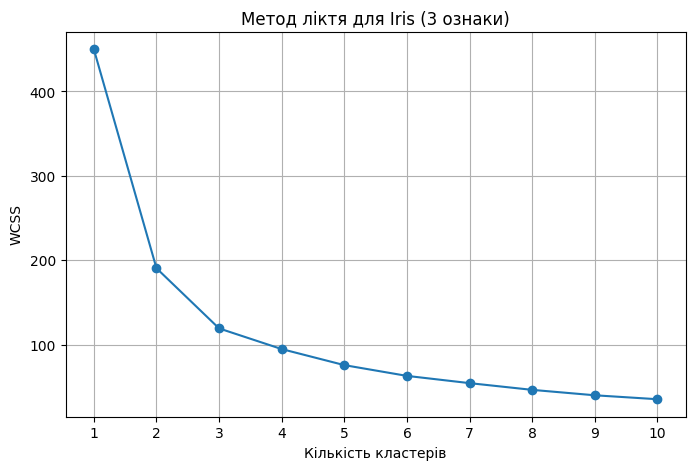

In [ ]:
# Для кластеризації використовуємо перші три ознаки Iris
X_iris = iris_df.iloc[:, :3]
scaler_iris = StandardScaler()
X_iris_scaled = scaler_iris.fit_transform(X_iris)

wcss_iris = []
for k in range(1, 11):
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    model.fit(X_iris_scaled)
    wcss_iris.append(model.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(range(1, 11), wcss_iris, marker='o')
plt.xlabel('Кількість кластерів')
plt.ylabel('WCSS')
plt.title('Метод ліктя для Iris (3 ознаки)')
plt.xticks(range(1, 11))
plt.grid(True)
plt.show()

**1.4. Метод силуетів.** Для тих самих трьох ознак Iris обчисліть середній коефіцієнт силуета для 2–10 кластерів і побудуйте графік.

,Кількість кластерів,Коефіцієнт силуета
0,2,0.552474
1,3,0.459432
2,4,0.405652
3,5,0.375498
4,6,0.377226
5,7,0.362828
6,8,0.381414
7,9,0.374861
8,10,0.379114


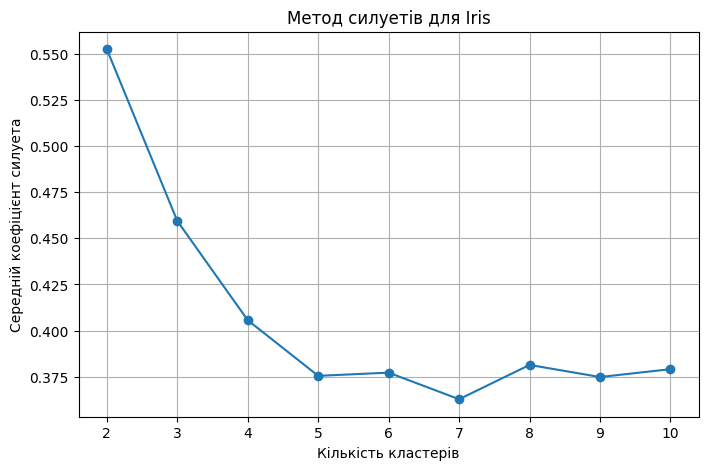

Найвище значення силуета: 2


In [ ]:
silhouette_iris = {}
for k in range(2, 11):
    labels = KMeans(n_clusters=k, random_state=42, n_init=10).fit_predict(X_iris_scaled)
    silhouette_iris[k] = silhouette_score(X_iris_scaled, labels)

display(pd.DataFrame({'Кількість кластерів': list(silhouette_iris.keys()),
                      'Коефіцієнт силуета': list(silhouette_iris.values())}))
plt.figure(figsize=(8, 5))
plt.plot(list(silhouette_iris.keys()), list(silhouette_iris.values()), marker='o')
plt.xlabel('Кількість кластерів')
plt.ylabel('Середній коефіцієнт силуета')
plt.title('Метод силуетів для Iris')
plt.xticks(range(2, 11))
plt.grid(True)
plt.show()
print('Найвище значення силуета:', max(silhouette_iris, key=silhouette_iris.get))

**1.5. Фінальна кластеризація та візуалізація.** Побудуйте K-Means для `n_clusters=2`  На площині покажіть перші дві з них та відповідні координати центрів. Це **двовимірне відображення результату кластеризації за трьома ознаками**.

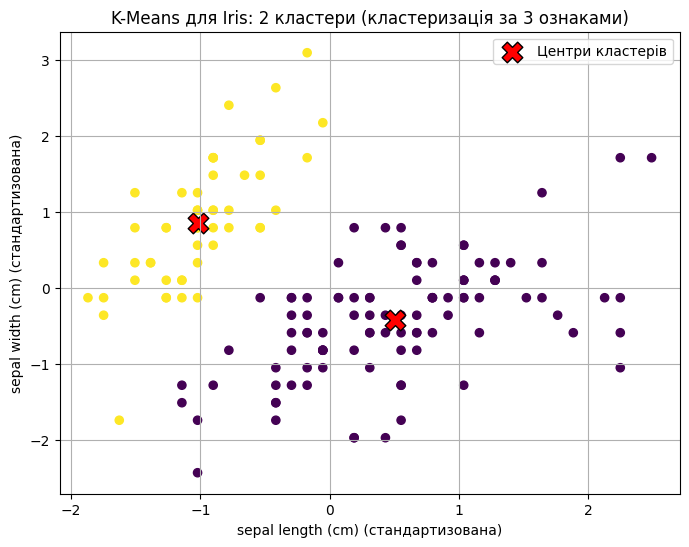

Кількість об’єктів у кластерах: {0: 100, 1: 50}


In [ ]:
kmeans_iris = KMeans(n_clusters=2, random_state=42, n_init=10)
labels_iris = kmeans_iris.fit_predict(X_iris_scaled)
centers_iris = kmeans_iris.cluster_centers_

plt.figure(figsize=(8, 6))
plt.scatter(X_iris_scaled[:, 0], X_iris_scaled[:, 1], c=labels_iris, cmap='viridis', s=35)
plt.scatter(centers_iris[:, 0], centers_iris[:, 1], c='red', marker='X', s=220,
            edgecolor='black', label='Центри кластерів')
plt.xlabel(iris.feature_names[0] + ' (стандартизована)')
plt.ylabel(iris.feature_names[1] + ' (стандартизована)')
plt.title('K-Means для Iris: 2 кластери (кластеризація за 3 ознаками)')
plt.legend()
plt.grid(True)
plt.show()
print('Кількість об’єктів у кластерах:', pd.Series(labels_iris).value_counts().sort_index().to_dict())

**Короткий висновок до завдання 1:** порівняйте результати методу ліктя й методу силуетів. Поясніть, чому обрано два кластери та чи збігається такий вибір з отриманими графіками.

## Завдання 2. Дослідження даних студентів

Спочатку порівняйте три класифікатори (як у початковій лабораторній роботі), а потім виконайте кластеризацію. **Класифікація та кластеризація — різні задачі:** у класифікації використовується цільова ознака `GradeClass`, а в кластеризації — ні.

**2.1. Імпорт бібліотек для класифікації.** Імпортуйте засоби для поділу даних, добору параметрів, класифікації та оцінювання моделей.

In [ ]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report
import os

from google.colab import files

**2.2. Завантаження файлу.** Помістіть `Student_data.csv` до робочої папки або завантажте його через Colab. Файл містить дані з Вашої початкової роботи.

In [ ]:
import sys, subprocess
try:
    import kagglehub
except ImportError:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', 'kagglehub'])
    import kagglehub

path = kagglehub.dataset_download("rabieelkharoua/students-performance-dataset")
print("Шлях до набору даних:", path)
csv_candidates = [f for f in os.listdir(path) if f.lower().endswith('.csv')]
print("CSV-файли:", csv_candidates)

Using Colab cache for faster access to the 'students-performance-dataset' dataset.
Шлях до набору даних: /kaggle/input/students-performance-dataset
CSV-файли: ['Student_performance_data _.csv']


**2.3. Перегляд даних.** Прочитайте CSV у DataFrame і перегляньте вміст.

In [ ]:
csv_path = os.path.join(path, 'Student_performance_data _.csv')
if not os.path.exists(csv_path):
    matches = [os.path.join(path, f) for f in os.listdir(path) if f.lower().endswith('.csv')]
    if not matches:
        raise FileNotFoundError('У завантаженому наборі не знайдено CSV-файл.')
    csv_path = matches[0]
df = pd.read_csv(csv_path)
display(df.head())

,StudentID,Age,Gender,Ethnicity,ParentalEducation,StudyTimeWeekly,Absences,Tutoring,ParentalSupport,Extracurricular,Sports,Music,Volunteering,GPA,GradeClass
0,1001,17,1,0,2,19.833723,7,1,2,0,0,1,0,2.929196,2.0
1,1002,18,0,0,1,15.408756,0,0,1,0,0,0,0,3.042915,1.0
2,1003,15,0,2,3,4.210570,26,0,2,0,0,0,0,0.112602,4.0
3,1004,17,1,0,3,10.028829,14,0,3,1,0,0,0,2.054218,3.0
4,1005,17,1,0,2,4.672495,17,1,3,0,0,0,0,1.288061,4.0


**2.4. Назви стовпців.** Виведіть назви всіх стовпців.

In [ ]:
print('Стовпці набору даних:')
print(df.columns.tolist())

Стовпці набору даних:
['StudentID', 'Age', 'Gender', 'Ethnicity', 'ParentalEducation', 'StudyTimeWeekly', 'Absences', 'Tutoring', 'ParentalSupport', 'Extracurricular', 'Sports', 'Music', 'Volunteering', 'GPA', 'GradeClass']


**2.5. Структура таблиці.** Перегляньте типи стовпців і кількість непорожніх значень.

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2392 entries, 0 to 2391
Data columns (total 15 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   StudentID          2392 non-null   int64  
 1   Age                2392 non-null   int64  
 2   Gender             2392 non-null   int64  
 3   Ethnicity          2392 non-null   int64  
 4   ParentalEducation  2392 non-null   int64  
 5   StudyTimeWeekly    2392 non-null   float64
 6   Absences           2392 non-null   int64  
 7   Tutoring           2392 non-null   int64  
 8   ParentalSupport    2392 non-null   int64  
 9   Extracurricular    2392 non-null   int64  
 10  Sports             2392 non-null   int64  
 11  Music              2392 non-null   int64  
 12  Volunteering       2392 non-null   int64  
 13  GPA                2392 non-null   float64
 14  GradeClass         2392 non-null   float64
dtypes: float64(3), int64(12)
memory usage: 280.4 KB


**2.6. Пропущені значення.** Перевірте, чи містить набір даних пропущені значення.

In [ ]:
print('Кількість пропусків у кожному стовпці:')
display(df.isna().sum())
print('Загальна кількість пропусків:', int(df.isna().sum().sum()))

Кількість пропусків у кожному стовпці:


,0
StudentID,0
Age,0
Gender,0
Ethnicity,0
ParentalEducation,0
StudyTimeWeekly,0
Absences,0
Tutoring,0
ParentalSupport,0
Extracurricular,0


Загальна кількість пропусків: 0


**2.7. Дублікати.** Обчисліть кількість дублікатів.

In [ ]:
print('Кількість повних дублікатів:', int(df.duplicated().sum()))

Кількість повних дублікатів: 0


**2.8. Описова статистика.** Виведіть основні описові статистики.

In [ ]:
display(df.describe(include='all').T)

,count,mean,std,min,25%,50%,75%,max
StudentID,2392.0,2196.500000,690.655244,1001.000000,1598.750000,2196.500000,2794.250000,3392.000000
Age,2392.0,16.468645,1.123798,15.000000,15.000000,16.000000,17.000000,18.000000
Gender,2392.0,0.510870,0.499986,0.000000,0.000000,1.000000,1.000000,1.000000
Ethnicity,2392.0,0.877508,1.028476,0.000000,0.000000,0.000000,2.000000,3.000000
ParentalEducation,2392.0,1.746237,1.000411,0.000000,1.000000,2.000000,2.000000,4.000000
StudyTimeWeekly,2392.0,9.771992,5.652774,0.001057,5.043079,9.705363,14.408410,19.978094
Absences,2392.0,14.541388,8.467417,0.000000,7.000000,15.000000,22.000000,29.000000
Tutoring,2392.0,0.301421,0.458971,0.000000,0.000000,0.000000,1.000000,1.000000
ParentalSupport,2392.0,2.122074,1.122813,0.000000,1.000000,2.000000,3.000000,4.000000
Extracurricular,2392.0,0.383361,0.486307,0.000000,0.000000,0.000000,1.000000,1.000000


**2.9. Підготовка даних для класифікації.** Сформуйте `X` та `y`, прибравши з ознак цільову змінну `GradeClass` і службовий ідентифікатор `StudentID`. Поділіть дані у співвідношенні 80/20 та стандартизуйте ознаки.

In [ ]:
import numpy as np
if 'GradeClass' not in df.columns:
    raise KeyError("У наборі даних відсутній стовпець GradeClass.")
X = df.drop(columns=['GradeClass', 'StudentID'], errors='ignore')
y = df['GradeClass']

X = pd.get_dummies(X, drop_first=False)
X = X.replace([np.inf, -np.inf], np.nan).fillna(X.median(numeric_only=True)).fillna(0)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)
print('Train:', X_train.shape, 'Test:', X_test.shape)
print('Кількість класів:', y.nunique())

Train: (1913, 13) Test: (479, 13)
Кількість класів: 5


### 2.10. Класифікація: Random Forest

**Модель Random Forest.** Здійсніть добір гіперпараметрів `GridSearchCV` (5 згорток), виведіть найкращі параметри, середню CV-точність і тестову accuracy. Пошук може тривати довше через велику сітку параметрів.

In [ ]:
rf = RandomForestClassifier(random_state=42, class_weight='balanced')
rf_params = {
    'n_estimators': [100, 200],
    'max_depth': [None, 10, 20],
    'min_samples_split': [2, 5],
    'min_samples_leaf': [1, 2]
}
rf_grid = GridSearchCV(rf, rf_params, cv=5, scoring='accuracy', n_jobs=-1)
rf_grid.fit(X_train, y_train)
rf_pred = rf_grid.predict(X_test)
rf_cv = rf_grid.best_score_
rf_test = accuracy_score(y_test, rf_pred)
print('Найкращі параметри Random Forest:', rf_grid.best_params_)
print(f'Середня CV accuracy: {rf_cv:.4f}')
print(f'Test accuracy: {rf_test:.4f}')

Найкращі параметри Random Forest: {'max_depth': None, 'min_samples_leaf': 2, 'min_samples_split': 5, 'n_estimators': 200}
Середня CV accuracy: 0.9289
Test accuracy: 0.9248


### 2.11. Класифікація: Logistic Regression

**Модель Logistic Regression.** Застосуйте `GridSearchCV` до логістичної регресії. Для багатокласової задачі використайте `saga` — `liblinear` у нових версіях sklearn не підтримує багатокласову класифікацію без додаткової обгортки.

In [ ]:
lr = LogisticRegression(solver='saga', max_iter=5000, random_state=42)
lr_params = {
    'C': [0.1, 1, 10],
    'penalty': ['l1', 'l2'],
    'class_weight': [None, 'balanced']
}
lr_grid = GridSearchCV(lr, lr_params, cv=5, scoring='accuracy', n_jobs=-1)
lr_grid.fit(X_train_scaled, y_train)
lr_pred = lr_grid.predict(X_test_scaled)
lr_cv = lr_grid.best_score_
lr_test = accuracy_score(y_test, lr_pred)
print('Найкращі параметри Logistic Regression:', lr_grid.best_params_)
print(f'Середня CV accuracy: {lr_cv:.4f}')
print(f'Test accuracy: {lr_test:.4f}')

### 2.12. Класифікація: Support Vector Machine

**Модель SVM.** Виконайте підбір параметрів SVM та обчисліть CV-точність і тестову accuracy.

In [ ]:
svm = SVC()
svm_params = {
    'C': [0.1, 1, 10],
    'kernel': ['linear', 'rbf'],
    'gamma': ['scale', 'auto']
}
svm_grid = GridSearchCV(svm, svm_params, cv=5, scoring='accuracy', n_jobs=-1)
svm_grid.fit(X_train_scaled, y_train)
svm_pred = svm_grid.predict(X_test_scaled)
svm_cv = svm_grid.best_score_
svm_test = accuracy_score(y_test, svm_pred)
print('Найкращі параметри SVM:', svm_grid.best_params_)
print(f'Середня CV accuracy: {svm_cv:.4f}')
print(f'Test accuracy: {svm_test:.4f}')

### 2.13. Порівняння результатів

**Порівняння моделей.** Порівняйте тестову точність трьох моделей. Оберіть модель **за найкращою CV-точністю**, а звіт `classification_report` виведіть один раз на тестових даних.

In [ ]:
results = pd.DataFrame({
    'Модель': ['Random Forest', 'Logistic Regression', 'SVM'],
    'CV accuracy': [rf_cv, lr_cv, svm_cv],
    'Test accuracy': [rf_test, lr_test, svm_test]
}).sort_values('CV accuracy', ascending=False).reset_index(drop=True)
display(results)
best_name = results.loc[0, 'Модель']
best_predictions = {'Random Forest': rf_pred,
                    'Logistic Regression': lr_pred,
                    'SVM': svm_pred}[best_name]
print('Модель, обрана за найкращою CV accuracy:', best_name)
print('\nClassification report для обраної моделі:')
print(classification_report(y_test, best_predictions, zero_division=0))

,Модель,CV accuracy,Test accuracy
0,Random Forest,0.928911,0.924843
1,SVM,0.852065,0.858038
2,Logistic Regression,0.802411,0.818372


Модель, обрана за найкращою CV accuracy: Random Forest

Classification report для обраної моделі:
              precision    recall  f1-score   support

         0.0       1.00      0.52      0.69        21
         1.0       0.91      0.89      0.90        54
         2.0       0.91      0.95      0.93        78
         3.0       0.89      0.89      0.89        83
         4.0       0.94      0.97      0.96       243

    accuracy                           0.92       479
   macro avg       0.93      0.84      0.87       479
weighted avg       0.93      0.92      0.92       479



### 2.14. Кластеризація даних студентів: метод ліктя

**Метод ліктя для студентів.** Для кластеризації використайте чотири числові ознаки `Age`, `StudyTimeWeekly`, `Absences`, `GPA`. Стандартизуйте їх і побудуйте графік WCSS для 1–10 кластерів.

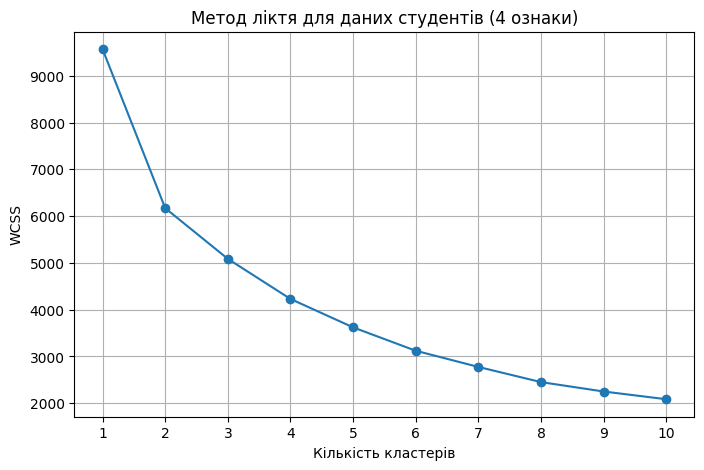

In [ ]:
cluster_features = ['Age', 'StudyTimeWeekly', 'Absences', 'GPA']
missing = [c for c in cluster_features if c not in df.columns]
if missing:
    raise KeyError(f'У наборі відсутні потрібні ознаки: {missing}')
X_students = df[cluster_features].apply(pd.to_numeric, errors='coerce')
X_students = X_students.fillna(X_students.median())
scaler_students = StandardScaler()
X_students_scaled = scaler_students.fit_transform(X_students)

wcss_students = []
for k in range(1, 11):
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(X_students_scaled)
    wcss_students.append(km.inertia_)
plt.figure(figsize=(8, 5))
plt.plot(range(1, 11), wcss_students, marker='o')
plt.xlabel('Кількість кластерів')
plt.ylabel('WCSS')
plt.title('Метод ліктя для даних студентів (4 ознаки)')
plt.xticks(range(1, 11))
plt.grid(True)
plt.show()

### 2.15. Кластеризація даних студентів: метод силуетів

**Метод силуетів для студентів.** Для тих самих чотирьох ознак побудуйте графік коефіцієнта силуета для 2–10 кластерів.

,Кількість кластерів,Коефіцієнт силуета
0,2,0.308033
1,3,0.270199
2,4,0.257958
3,5,0.264465
4,6,0.268880
5,7,0.269234
6,8,0.271153
7,9,0.273219
8,10,0.272498


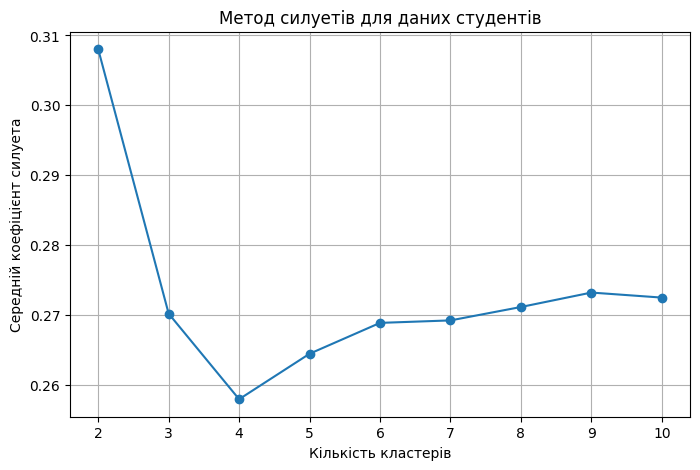

Найвище значення силуета отримано для k = 2


In [ ]:
silhouette_students = {}
for k in range(2, 11):
    labels = KMeans(n_clusters=k, random_state=42, n_init=10).fit_predict(X_students_scaled)
    silhouette_students[k] = silhouette_score(X_students_scaled, labels)
display(pd.DataFrame({'Кількість кластерів': list(silhouette_students.keys()),
                      'Коефіцієнт силуета': list(silhouette_students.values())}))
plt.figure(figsize=(8, 5))
plt.plot(list(silhouette_students.keys()), list(silhouette_students.values()), marker='o')
plt.xlabel('Кількість кластерів')
plt.ylabel('Середній коефіцієнт силуета')
plt.title('Метод силуетів для даних студентів')
plt.xticks(range(2, 11))
plt.grid(True)
plt.show()
print('Найвище значення силуета отримано для k =', max(silhouette_students, key=silhouette_students.get))

### 2.16. Додатковий підхід: PCA та автоматичне визначення точки ліктя

Тут використовується **інший набір ознак**: усі стовпці, крім `StudentID` та `GradeClass`. Після PCA кластеризацію проведемо за вибраними головними компонентами.

**Установлення додаткових пакетів.** За потреби встановіть `kneed` і `yellowbrick` у середовищі ноутбука.

In [ ]:

import sys, subprocess
for package in ['kneed', 'yellowbrick']:
    try:
        __import__(package)
    except ImportError:
        subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', package])

**Імпорт PCA і KneeLocator.** Імпортуйте `PCA`, `KneeLocator` та `numpy`.

In [ ]:
import numpy as np
from sklearn.decomposition import PCA
from kneed import KneeLocator

**Підготовка всіх ознак.** Приберіть `StudentID` і `GradeClass`, залишивши ознаки для PCA.

In [ ]:
X_pca = df.drop(columns=['StudentID', 'GradeClass'], errors='ignore')
X_pca = pd.get_dummies(X_pca, drop_first=False)
X_pca = X_pca.apply(pd.to_numeric, errors='coerce')
X_pca = X_pca.replace([np.inf, -np.inf], np.nan)
X_pca = X_pca.fillna(X_pca.median()).fillna(0)
print('Розмір матриці ознак для PCA:', X_pca.shape)

Розмір матриці ознак для PCA: (2392, 13)


**Модель PCA.** Стандартизуйте ознаки, навчіть PCA та знайдіть частку поясненої дисперсії кожної компоненти.

In [ ]:
scaler_pca = StandardScaler()
X_pca_scaled = scaler_pca.fit_transform(X_pca)
pca_full = PCA()
pca_full.fit(X_pca_scaled)
explained_variance = pca_full.explained_variance_ratio_
display(pd.DataFrame({'Компонента': np.arange(1, len(explained_variance)+1),
                      'Частка поясненої дисперсії': explained_variance}))

,Компонента,Частка поясненої дисперсії
0,1,0.152469
1,2,0.086114
2,3,0.082679
3,4,0.080718
4,5,0.078648
5,6,0.077931
6,7,0.076308
7,8,0.076004
8,9,0.074409
9,10,0.073798


**Визначення кількості компонент.** Застосуйте `KneeLocator` до часток поясненої дисперсії. У підписі графіка вказуйте номер компоненти без додавання одиниці.

Кількість компонент за KneeLocator (або fallback 85%): 2


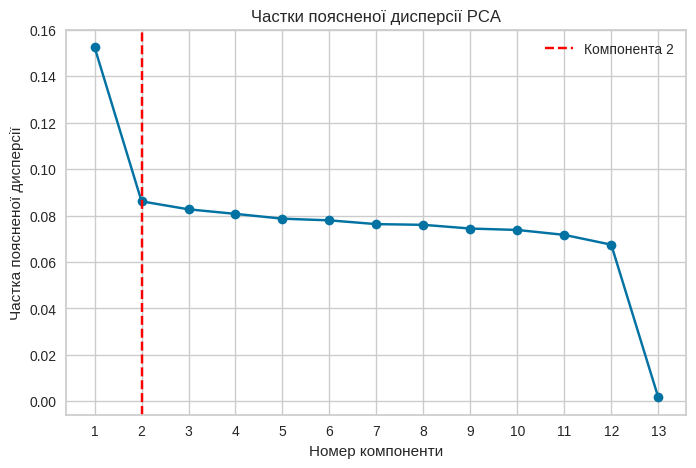

In [ ]:
components = np.arange(1, len(explained_variance) + 1)
knee = KneeLocator(components, explained_variance, curve='convex', direction='decreasing')
n_components_knee = knee.knee
if n_components_knee is None:
    n_components_knee = int(np.argmax(np.cumsum(explained_variance) >= 0.85) + 1)
print('Кількість компонент за KneeLocator (або fallback 85%):', n_components_knee)
plt.figure(figsize=(8, 5))
plt.plot(components, explained_variance, marker='o')
plt.axvline(n_components_knee, color='red', linestyle='--', label=f'Компонента {n_components_knee}')
plt.xlabel('Номер компоненти')
plt.ylabel('Частка поясненої дисперсії')
plt.title('Частки поясненої дисперсії PCA')
plt.xticks(components)
plt.legend()
plt.grid(True)
plt.show()

**Кумулятивна пояснена дисперсія.** На горизонтальній осі має бути **кількість головних компонент** (1, 2, 3, ...), тому індекс масиву для `n_components` дорівнює `n_components - 1`.

**Кумулятивна дисперсія та перетворення PCA.** Побудуйте графік кумулятивної дисперсії та позначте знайдену кількість компонент. Виведіть фактичну частку дисперсії. Перетворіть ознаки через PCA для наступного етапу.

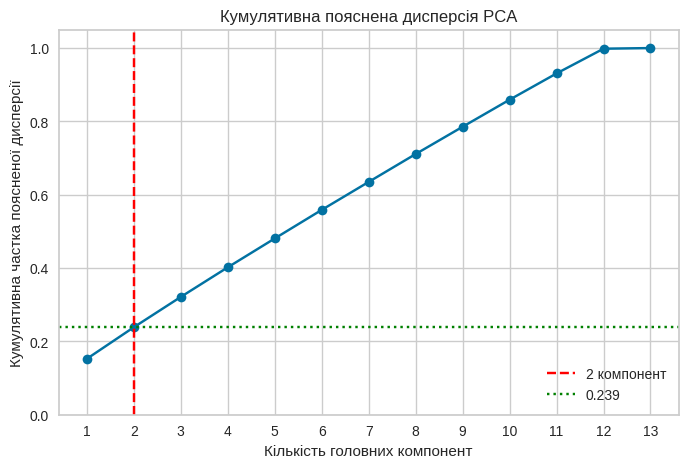

2 компонент пояснюють 0.2386 (23.86%) дисперсії.
Розмір даних після PCA: (2392, 2)


In [ ]:
cumulative_variance = np.cumsum(explained_variance)
n_components = int(n_components_knee)
explained_by_selected = cumulative_variance[n_components - 1]
plt.figure(figsize=(8, 5))
plt.plot(np.arange(1, len(cumulative_variance)+1), cumulative_variance, marker='o')
plt.axvline(n_components, color='red', linestyle='--', label=f'{n_components} компонент')
plt.axhline(explained_by_selected, color='green', linestyle=':', label=f'{explained_by_selected:.3f}')
plt.xlabel('Кількість головних компонент')
plt.ylabel('Кумулятивна частка поясненої дисперсії')
plt.title('Кумулятивна пояснена дисперсія PCA')
plt.xticks(np.arange(1, len(cumulative_variance)+1))
plt.ylim(0, 1.05)
plt.legend()
plt.grid(True)
plt.show()
print(f'{n_components} компонент пояснюють {explained_by_selected:.4f} ({explained_by_selected*100:.2f}%) дисперсії.')
pca = PCA(n_components=n_components, random_state=42)
X_pca_reduced = pca.fit_transform(X_pca_scaled)
print('Розмір даних після PCA:', X_pca_reduced.shape)

Зауваження: кумулятивна пояснена дисперсія — це **частка дисперсії**, а не відсоток «інформативності» даних. Значення потрібно брати з розрахунку, а не задавати наперед (наприклад, 32%).

**Імпорт KElbowVisualizer.** Імпортуйте `KElbowVisualizer` із `yellowbrick.cluster`.

In [ ]:
from yellowbrick.cluster import KElbowVisualizer

**Метод ліктя після PCA.** Побудуйте графік `KElbowVisualizer` для K-Means. Для узгодженості з попереднім етапом використайте **дані після PCA**.

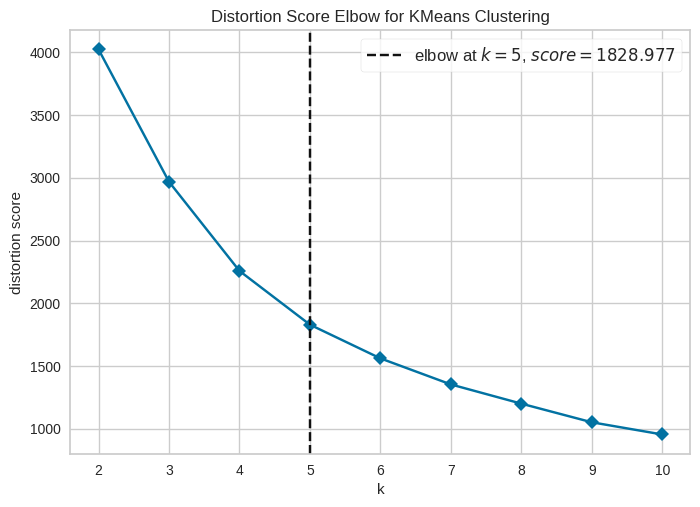

Оптимальна кількість кластерів за KElbowVisualizer: 5


In [ ]:
kmeans_pca = KMeans(random_state=42, n_init=10)
visualizer = KElbowVisualizer(kmeans_pca, k=(2, 11), metric='distortion', timings=False)
visualizer.fit(X_pca_reduced)
visualizer.show()
print('Оптимальна кількість кластерів за KElbowVisualizer:', visualizer.elbow_value_)

## Висновки

Порівняйте результати різних способів визначення кількості кластерів та сформулюйте короткі висновки. Для завдання 2 окремо поясніть різницю між класифікацією за `GradeClass` і кластеризацією без цільової змінної. Зазначте, скільки головних компонент обрано та яку частку дисперсії вони пояснюють.

## Висновки

1. **Iris.** K-Means розподілив об’єкти на два кластери за трьома стандартизованими ознаками. Метод ліктя оцінює зміну WCSS, а коефіцієнт силуета — компактність і розділеність кластерів. Остаточний вибір слід обґрунтувати фактичними графіками та значеннями, отриманими під час запуску.
2. **Класифікація студентів.** Класифікація є навчанням із учителем: модель використовує `GradeClass` як відому цільову змінну та прогнозує її. Три моделі порівнюються за середньою CV accuracy і тестовою accuracy; найкраща модель обирається саме за CV accuracy.
3. **Кластеризація студентів.** На відміну від класифікації, кластеризація не використовує `GradeClass`. Для K-Means використано лише `Age`, `StudyTimeWeekly`, `Absences`, `GPA`. Кількість кластерів аналізується за графіками WCSS і коефіцієнта силуета.
4. **PCA.** Для додаткового етапу використано всі ознаки, крім `StudentID` та `GradeClass`. PCA зменшує розмірність, зберігаючи якомога більшу частку дисперсії. Кількість компонент і фактична кумулятивна частка дисперсії виводяться програмно; їх потрібно навести у звіті за результатами запуску.
5. **Автоматичний метод ліктя.** `KElbowVisualizer` застосовується до даних після PCA, тому результат цього етапу можна порівнювати з попереднім аналізом PCA, а не з кластеризацією лише за чотирма окремими ознаками.